
# Тест 01: Supervised  learning (Обучение с учителем)

Этот тест предназначен для оценки ваших знаний об импорте данных, их визуализации и использовании моделей машинного обучения.
Пожалуйста, введите ответы непосредственно в ячейки, предназначенные для каждого раздела.


## 1. Импорт данных
    1. Импортируйте библиотеку `pandas` и загрузите файл `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
    2. Проверьте размерности и типы данных.
    3. Выведите первые 5 строк DataFrame и проверьте наличие пропущенных значений.


In [1]:
import pandas as pd
import numpy as np

# датасет с Kaggle разбит на train.csv и test.csv, объединяем их в один DataFrame
train = pd.read_csv('archive/train.csv')
test = pd.read_csv('archive/test.csv')
df = pd.concat([train, test], ignore_index=True)

print('Размерность:', df.shape)
print(df.dtypes.value_counts())

display(df.head())

print('Пропущенных значений:', df.isnull().sum().sum())
print(df['Activity'].value_counts())

Размерность: (10299, 563)
float64    561
int64        1
str          1
Name: count, dtype: int64


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


Пропущенных значений: 0
Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64



## 2. Визуализация данных с помощью Matplotlib и Seaborn
1. Создайте точечную диаграмму (scatter plot) для отображения связи между двумя числовыми столбцами.
2. Используйте Seaborn для создания тепловой карты (heatmap) корреляций между столбцами.

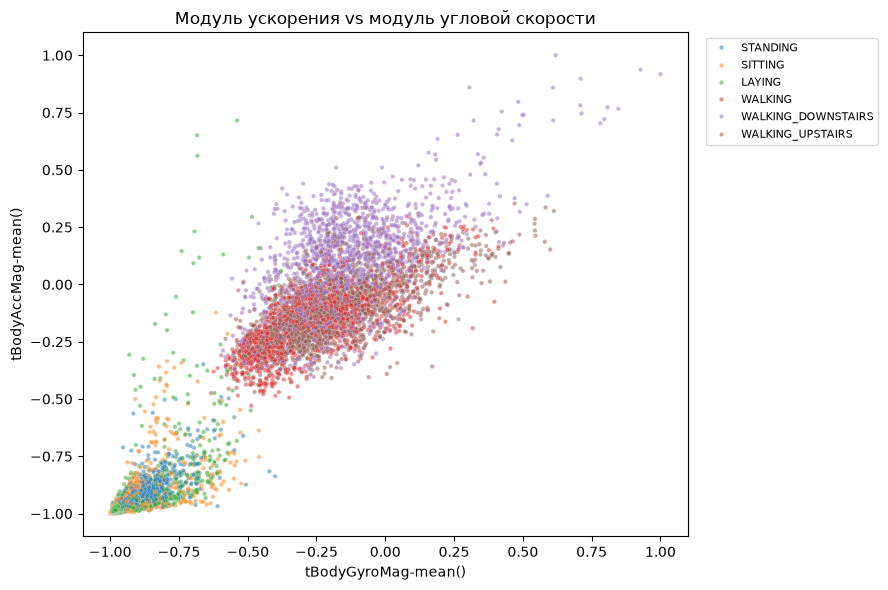

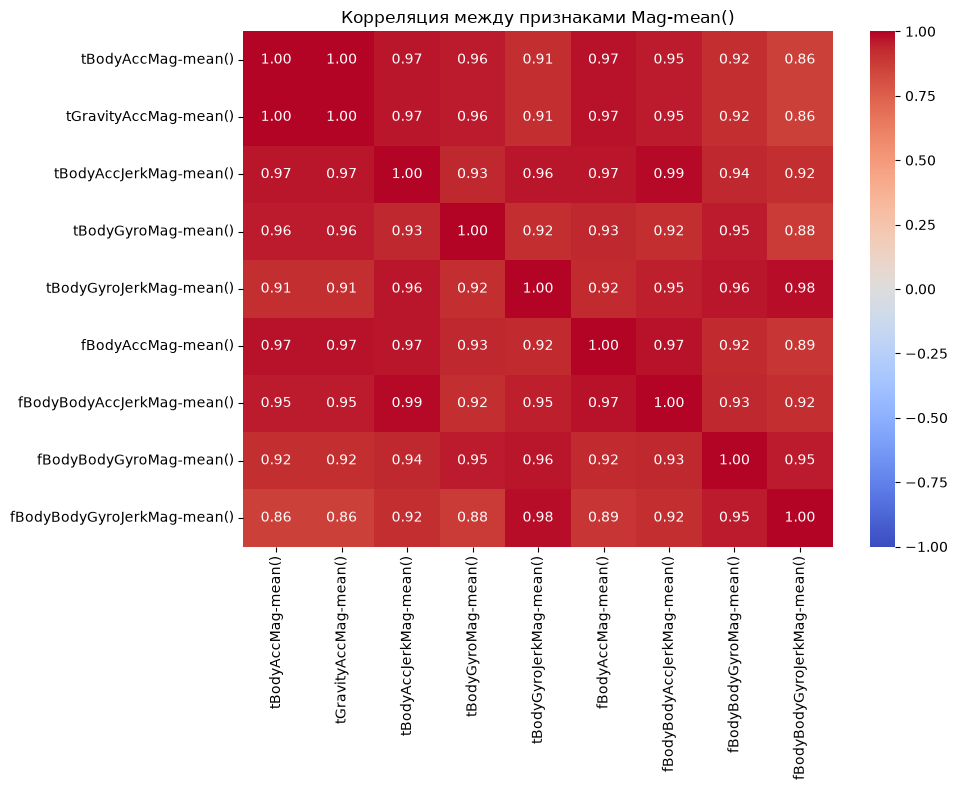

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='tBodyGyroMag-mean()', y='tBodyAccMag-mean()',
                hue='Activity', s=10, alpha=0.5)
plt.title('Модуль ускорения vs модуль угловой скорости')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

# 561 признак на одной карте не читается, берём средние значения модулей сигналов
mag_cols = [c for c in df.columns if 'Mag-mean()' in c]
corr = df[mag_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляция между признаками Mag-mean()')
plt.tight_layout()
plt.show()

## 3. Метрики ошибки
1. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
2. Постройте модель линейной регрессии на числовых данных.
3. Оцените производительность модели с использованием **MAE**, **MSE** и **RMSE**.

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# регрессия: предсказываем модуль ускорения тела по признакам гироскопа
feature_cols = df.select_dtypes(include='number').columns.drop('subject')
target = 'tBodyAccMag-mean()'
gyro_cols = [c for c in feature_cols if 'Gyro' in c]

X = df[gyro_cols]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, 'Test:', X_test.shape)

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f'MAE  = {mae:.4f}')
print(f'MSE  = {mse:.4f}')
print(f'RMSE = {rmse:.4f}')
print(f'Стандартное отклонение целевой переменной: {y.std():.4f}')

Train: (8239, 213) Test: (2060, 213)
MAE  = 0.0568
MSE  = 0.0090
RMSE = 0.0949
Стандартное отклонение целевой переменной: 0.4671



## 4. Перекрёстная проверка (Cross Validation)
1. Импортируйте библиотеку `scikit-learn`.
2. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
3. Используйте `cross_val_score` для оценки производительности модели KNN на наборе данных.


Train: (8239, 561) Test: (2060, 561)


Accuracy по фолдам: [0.9684 0.9636 0.966  0.966  0.9654]
Средняя accuracy: 0.9659 ± 0.0016
Accuracy на тестовой выборке: 0.9646


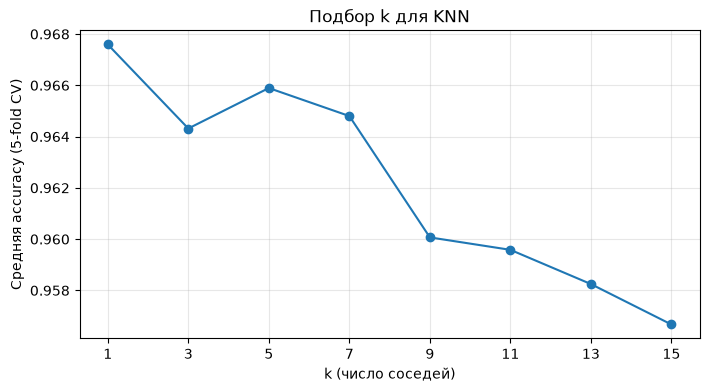

Лучшее k = 1, accuracy = 0.9676


In [4]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# классификация вида активности по всем 561 признакам
X_cls = df[feature_cols]
y_cls = df['Activity']

X_tr, X_te, y_tr, y_te = train_test_split(X_cls, y_cls, test_size=0.2,
                                          random_state=42, stratify=y_cls)
print('Train:', X_tr.shape, 'Test:', X_te.shape)

knn = KNeighborsClassifier(n_neighbors=5)
cv_scores = cross_val_score(knn, X_tr, y_tr, cv=5, scoring='accuracy')
print('Accuracy по фолдам:', cv_scores.round(4))
print(f'Средняя accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')

knn.fit(X_tr, y_tr)
knn_acc = knn.score(X_te, y_te)
print(f'Accuracy на тестовой выборке: {knn_acc:.4f}')

# подбор k по средней accuracy на кросс-валидации
k_values = range(1, 16, 2)
k_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_tr, y_tr, cv=5).mean()
            for k in k_values]

plt.figure(figsize=(8, 4))
plt.plot(k_values, k_scores, marker='o')
plt.xlabel('k (число соседей)')
plt.ylabel('Средняя accuracy (5-fold CV)')
plt.title('Подбор k для KNN')
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

best_k = list(k_values)[int(np.argmax(k_scores))]
print(f'Лучшее k = {best_k}, accuracy = {max(k_scores):.4f}')

По графику лучшее k = 1 (0.968), но k = 5 почти такое же (0.966), разница меньше 0.2%, поэтому я оставил k = 5. Начиная с k = 9 точность уже падает.

Думаю, k = 1 выигрывает из-за самих данных: окна сигнала перекрываются на 50%, и соседние строки одного человека получаются почти одинаковыми. При случайном разбиении 80/20 такие строки попадают и в train, и в test, поэтому ближайший сосед почти всегда угадывает. Если бы делили по `subject`, результат скорее всего был бы хуже.


## 5. Модели машинного обучения
1. **Линейная регрессия**: Обучите модель линейной регрессии и оцените ее производительность на тестовой выборке.
2. **Логистическая регрессия**: Постройте логистическую модель для задачи бинарной классификации.
3. **SVM**: Обучите модель SVM и протестируйте ее на наборе данных.

R2 train = 0.9650
R2 test  = 0.9587
RMSE train = 0.0874
RMSE test  = 0.0949


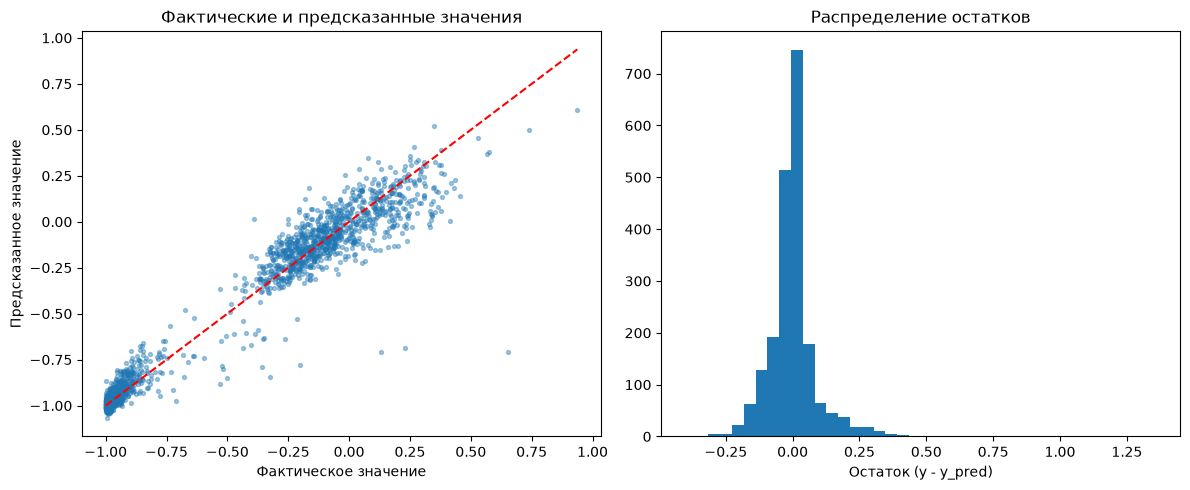

In [5]:
# модель из раздела 3: сравниваем качество на train и test
y_pred_train = lr.predict(X_train)
print(f'R2 train = {r2_score(y_train, y_pred_train):.4f}')
print(f'R2 test  = {r2_score(y_test, y_pred):.4f}')
print(f'RMSE train = {np.sqrt(mean_squared_error(y_train, y_pred_train)):.4f}')
print(f'RMSE test  = {rmse:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test, y_pred, s=8, alpha=0.4)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_xlabel('Фактическое значение')
axes[0].set_ylabel('Предсказанное значение')
axes[0].set_title('Фактические и предсказанные значения')

axes[1].hist(y_test - y_pred, bins=40)
axes[1].set_xlabel('Остаток (y - y_pred)')
axes[1].set_title('Распределение остатков')
plt.tight_layout()
plt.show()

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# бинарная задача: SITTING vs STANDING - самая трудная для разделения пара классов
bin_df = df[df['Activity'].isin(['SITTING', 'STANDING'])]
X_bin = bin_df[feature_cols]
y_bin = (bin_df['Activity'] == 'STANDING').astype(int)

Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X_bin, y_bin, test_size=0.2,
                                              random_state=42, stratify=y_bin)

log_bin = LogisticRegression(max_iter=1000)
log_bin.fit(Xb_tr, yb_tr)
yb_pred = log_bin.predict(Xb_te)

print(f'Accuracy: {accuracy_score(yb_te, yb_pred):.4f}')
print(classification_report(yb_te, yb_pred, target_names=['SITTING', 'STANDING']))

Accuracy: 0.9471
              precision    recall  f1-score   support

     SITTING       0.96      0.93      0.94       356
    STANDING       0.94      0.96      0.95       381

    accuracy                           0.95       737
   macro avg       0.95      0.95      0.95       737
weighted avg       0.95      0.95      0.95       737



In [7]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', C=1.0)
svm.fit(X_tr, y_tr)
y_pred_svm = svm.predict(X_te)
svm_acc = accuracy_score(y_te, y_pred_svm)

print(f'Accuracy: {svm_acc:.4f}')
print(classification_report(y_te, y_pred_svm))

Accuracy: 0.9757
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       389
           SITTING       0.93      0.95      0.94       356
          STANDING       0.95      0.93      0.94       381
           WALKING       1.00      1.00      1.00       344
WALKING_DOWNSTAIRS       0.99      0.99      0.99       281
  WALKING_UPSTAIRS       0.99      0.99      0.99       309

          accuracy                           0.98      2060
         macro avg       0.98      0.98      0.98      2060
      weighted avg       0.98      0.98      0.98      2060



## 6. Матрица ошибок (Confusion Matrix)
1. Постройте модель логистической классификации.
2. Создайте матрицу ошибок и отобразите ее графически с помощью Seaborn.

Accuracy: 0.9864


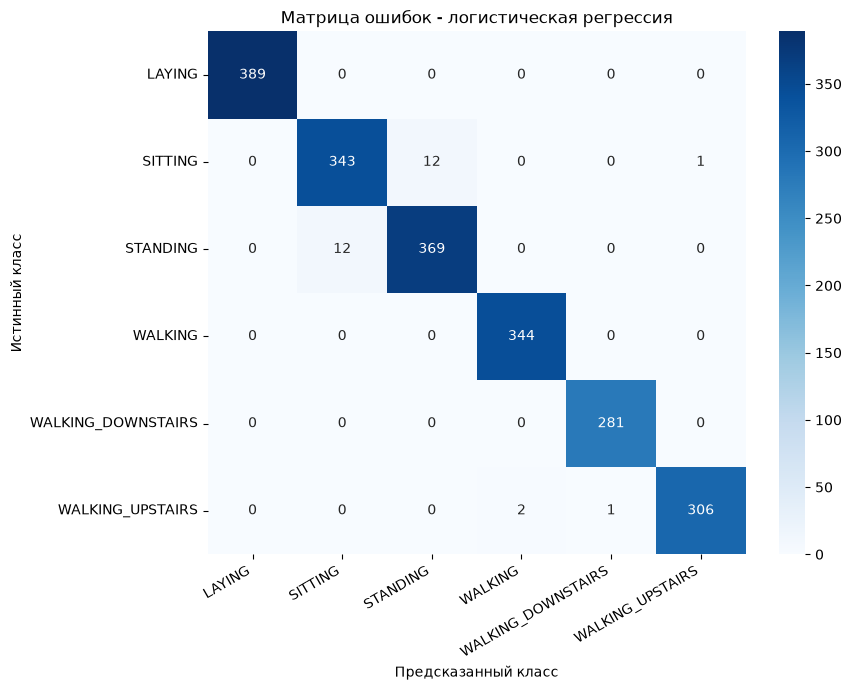

In [8]:
from sklearn.metrics import confusion_matrix

# многоклассовая логистическая регрессия по всем 6 видам активности
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_tr, y_tr)
y_pred_log = log_reg.predict(X_te)
log_acc = accuracy_score(y_te, y_pred_log)
print(f'Accuracy: {log_acc:.4f}')

labels = log_reg.classes_
cm = confusion_matrix(y_te, y_pred_log, labels=labels)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.title('Матрица ошибок - логистическая регрессия')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


## 7. Градиентный спуск (Gradient Descent)
1. Реализуйте алгоритм градиентного спуска вручную для оптимизации заданной функции стоимости.
2. Используйте простую функцию $$J(\theta) = (\theta x - y)^2$$ на подмножестве данных.

theta (градиентный спуск) = 0.9500
theta (аналитически)      = 0.9501
J(theta) = 0.0974


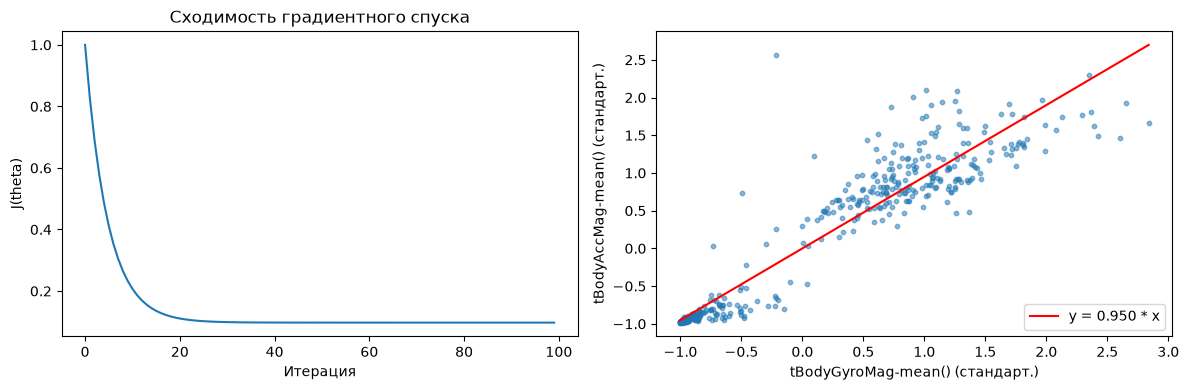

In [9]:
# J(theta) = mean((theta * x - y)^2)
# dJ/dtheta = mean(2 * x * (theta * x - y))
sample = df.sample(500, random_state=42)
x = sample['tBodyGyroMag-mean()'].values
y_gd = sample['tBodyAccMag-mean()'].values

# стандартизация, чтобы модель без свободного члена имела смысл
x = (x - x.mean()) / x.std()
y_gd = (y_gd - y_gd.mean()) / y_gd.std()

theta = 0.0
alpha = 0.05
n_iter = 100
cost_history = []

for i in range(n_iter):
    error = theta * x - y_gd
    cost_history.append(np.mean(error ** 2))
    grad = np.mean(2 * x * error)
    theta = theta - alpha * grad

theta_exact = np.sum(x * y_gd) / np.sum(x ** 2)
print(f'theta (градиентный спуск) = {theta:.4f}')
print(f'theta (аналитически)      = {theta_exact:.4f}')
print(f'J(theta) = {np.mean((theta * x - y_gd) ** 2):.4f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(cost_history)
axes[0].set_xlabel('Итерация')
axes[0].set_ylabel('J(theta)')
axes[0].set_title('Сходимость градиентного спуска')

axes[1].scatter(x, y_gd, s=10, alpha=0.5)
x_line = np.linspace(x.min(), x.max(), 100)
axes[1].plot(x_line, theta * x_line, 'r', label=f'y = {theta:.3f} * x')
axes[1].set_xlabel('tBodyGyroMag-mean() (стандарт.)')
axes[1].set_ylabel('tBodyAccMag-mean() (стандарт.)')
axes[1].legend()
plt.tight_layout()
plt.show()

## 8. Модели машинного обучения (part 2 - poate fi omis)
3. **Случайный лес (Random Forest)**: Используйте Random Forest для обучения модели и оцените важность признаков.
4. **Бустинг и бэггинг**: Сравните производительность моделей AdaBoost и Bagging.,

Random Forest accuracy: 0.9806


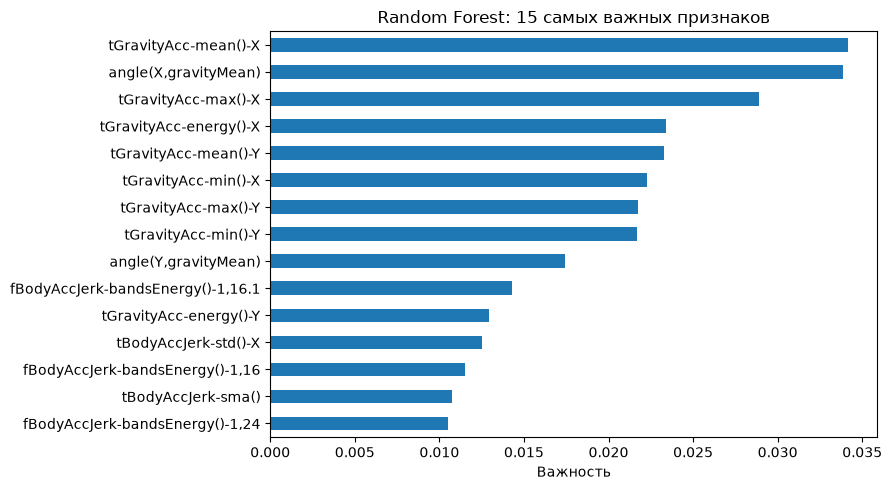

AdaBoost accuracy: 0.9883
Bagging accuracy:  0.9650
AdaBoost               0.9883
Logistic Regression    0.9864
Random Forest          0.9806
SVM                    0.9757
Bagging                0.9650
KNN                    0.9646
dtype: float64


In [10]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)
rf_acc = rf.score(X_te, y_te)
print(f'Random Forest accuracy: {rf_acc:.4f}')

importances = pd.Series(rf.feature_importances_, index=feature_cols).nlargest(15)
plt.figure(figsize=(9, 5))
importances.sort_values().plot(kind='barh')
plt.title('Random Forest: 15 самых важных признаков')
plt.xlabel('Важность')
plt.tight_layout()
plt.show()

# со стандартными пнями (max_depth=1) AdaBoost на 6 классах даёт около 0.41, поэтому деревья глубины 3
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3),
                         n_estimators=100, learning_rate=0.5, random_state=42)
ada.fit(X_tr, y_tr)
ada_acc = ada.score(X_te, y_te)

bag = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=50,
                        random_state=42, n_jobs=-1)
bag.fit(X_tr, y_tr)
bag_acc = bag.score(X_te, y_te)

print(f'AdaBoost accuracy: {ada_acc:.4f}')
print(f'Bagging accuracy:  {bag_acc:.4f}')

results = pd.Series({
    'KNN': knn_acc,
    'Logistic Regression': log_acc,
    'SVM': svm_acc,
    'Random Forest': rf_acc,
    'AdaBoost': ada_acc,
    'Bagging': bag_acc,
}).sort_values(ascending=False)
print(results.round(4))

## 9. Стекинг (Stacking) (poate fi omis)
1. Постройте модель стекинга, используя Random Forest, SVM и логистическую регрессию в качестве базовых моделей.
2. Используйте модель логистической регрессии в качестве мета-модели.
3. Выведите итоговую точность на тестовой выборке.

In [11]:
from sklearn.ensemble import StackingClassifier

base_models = [
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    ('svm', SVC(kernel='rbf', C=1.0)),
    ('lr', LogisticRegression(max_iter=1000)),
]

stack = StackingClassifier(estimators=base_models,
                           final_estimator=LogisticRegression(max_iter=1000),
                           cv=5, n_jobs=-1)
stack.fit(X_tr, y_tr)
stack_acc = stack.score(X_te, y_te)
print(f'Stacking accuracy: {stack_acc:.4f}')

Stacking accuracy: 0.9893



## Observații
Te rog, să salvezi  și să predai acest notebook după ce ai completat toate secțiunile.
